# 04 Statistical analysis

> **Synthetic data, sampled simulation.** 768 simulated runs compared with 19,708 scheduled runs (3.9%). Not IRCTC or Indian Railways network-wide data. No forecasts. Associations are not causes.

Each test states the **question**, the **metric** and unit of analysis, the **method**, the result with an **effect size** (with 10^5 bookings almost any difference is 'significant'), an **interpretation** and the **limitation**. p-values are also Bonferroni-adjusted for the number of tests. Because the data is synthetic, the generator's built-in relationships (assumption A-20) explain what is found: the notebook demonstrates method.

In [1]:
# Setup: find the project root, make python/src importable, load shared helpers (the data is only READ)
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data" / "processed" / "cleaned").exists())
sys.path.insert(0, str(ROOT / "python" / "src"))
import pandas as pd, numpy as np
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from analytics import data_loader as dl, validation, cleaning, kpi, eda, SYNTHETIC_NOTE
from analytics import statistics as stats
print(SYNTHETIC_NOTE)
%matplotlib inline
from IPython.display import Image, display

Synthetic data, sampled simulation (768 simulated runs of 19,708 scheduled). Not IRCTC or Indian Railways network-wide data; no forecasts.


In [2]:
ds = dl.load_dataset()
clean = cleaning.run_cleaning(ds.tables); facts = clean.facts
monthly = kpi.monthly_kpis(facts)
pf, bf, ef, cf, rf = (facts[k] for k in ("passenger_fact", "booking_fact", "event_fact", "class_run_fact", "run_fact"))
S = stats.run_statistics(facts, monthly)

## 1. Descriptive statistics

Mean, median, standard deviation, variance, percentiles and skewness.

In [3]:
display(S['descriptive'].set_index('variable'))

,n,mean,median,std,variance,min,p5,p25,p75,p95,max,skew,cv
variable,,,,,,,,,,,,,
fare per passenger (INR),"405,200.0000","1,512.7516","1,053.0000","1,071.5727","1,148,268.1287",144.0000,435.0000,753.0000,"2,211.0000","3,694.0000","7,338.0000",1.3192,0.7084
booking total fare (INR),"201,182.0000","3,046.8280","2,098.0000","3,083.4655","9,507,759.7637",173.0000,549.0000,"1,087.0000","3,691.0000","9,152.0000","44,028.0000",2.7087,1.0120
passengers per booking,"201,182.0000",2.0141,2.0000,1.2685,1.6090,1.0000,1.0000,1.0000,3.0000,4.0000,6.0000,1.3486,0.6298
booking lead time (days),"201,182.0000",31.3437,23.0000,28.5260,813.7302,0.0000,1.0000,9.0000,46.0000,97.0000,120.0000,1.2336,0.9101
class-run occupancy,"2,285.0000",0.7360,0.7609,0.2362,0.0558,0.1204,0.3261,0.5417,0.9861,1.0000,1.0000,-0.4085,0.3209
passengers per simulated run,768.0000,527.6042,478.0000,244.5186,"59,789.3425",131.0000,212.0500,342.0000,681.0000,980.6500,"1,399.0000",0.8722,0.4635
run occupancy,768.0000,0.7379,0.7613,0.1981,0.0392,0.2529,0.3826,0.5809,0.9078,0.9976,1.0000,-0.4082,0.2685
"arrival delay (min, recorded)",745.0000,15.6510,-1.0000,51.4299,"2,645.0340",-20.0000,-12.0000,-6.0000,17.0000,91.8000,715.0000,5.8821,3.2860
refund per event (INR),"43,923.0000","2,437.9830","1,570.0000","2,591.9259","6,718,080.0196",54.0000,484.0000,840.0000,"2,969.0000","7,617.5000","42,588.0000",3.0285,1.0631


## 2. Confidence intervals for the headline rates

The passenger cancellation rate is shown twice: the Wilson interval assumes independent passengers; the cluster bootstrap resamples whole bookings because passengers of one booking are not independent. The cluster interval is wider.

In [4]:
display(S['rate_cis'])

,measure,estimate,ci_low,ci_high,n
0,"passenger cancellation rate (Wilson, assumes i...",0.1382,0.1371,0.1392,405200
1,passenger cancellation rate (cluster bootstrap...,0.1382,0.1365,0.1399,201182
2,booking-based cancellation rate (Wilson),0.1323,0.1308,0.1338,201182
3,waitlist clearance rate (Wilson),0.1922,0.1882,0.1962,36876
4,on-time performance (Wilson),0.7477,0.7152,0.7775,745
5,seat occupancy (bootstrap over runs),0.7349,0.7195,0.7488,768
6,passengers per simulated run (bootstrap over r...,527.6042,509.5164,544.1387,768
7,"mean fare per passenger, INR (t interval)","1,512.7516","1,509.4522","1,516.0510",405200


## 3. Hypothesis tests

In [5]:
t = S['tests']
display(t[['test_id', 'question', 'method', 'n', 'p_value', 'p_bonferroni', 'effect_size_name', 'effect_size']])

,test_id,question,method,n,p_value,p_bonferroni,effect_size_name,effect_size
0,S-01,Do simulated runs on weekend days carry a diff...,Welch t-test (+ Mann-Whitney U as a robustness...,180 weekend / 588 weekday runs,0.0537,0.5910,Cohen's d,-0.1492
1,S-02,Do runs inside peak travel periods carry more ...,Welch t-test (+ Mann-Whitney U),161 peak / 607 other runs,0.0000,0.0000,Cohen's d,0.5915
2,S-03,Is seat occupancy higher on runs inside peak t...,Welch t-test (+ Mann-Whitney U),161 peak / 607 other runs,0.0000,0.0000,Cohen's d,0.7210
3,S-04,Is the share of fully cancelled bookings relat...,chi-square test of independence (+ Cramer's V),"201,182 bookings",0.0000,0.0000,Cramer's V,0.1103
4,S-05,Does seat occupancy differ between travel clas...,Kruskal-Wallis H test (rank-based; occupancy i...,"2,285 class-runs in 6 classes",0.0000,0.0000,epsilon-squared,0.0264
5,S-06,Does the arrival delay differ between seasons?,Kruskal-Wallis H test (delays are skewed),745 runs in 4 seasons,0.0788,0.8670,epsilon-squared,0.0051
6,S-07,Does the share of on-time runs (arrival delay ...,chi-square test of independence (+ Cramer's V),745 runs,0.2057,1.0000,Cramer's V,0.0784
7,S-08,Is there a linear trend in bookings per simula...,ordinary least squares slope on the month inde...,24 months,0.0315,0.3470,R-squared,0.1934
8,S-09,How strongly is the fare per passenger related...,Spearman rank correlation (+ Fisher-z CI),"201,182 bookings",0.0000,0.0000,Spearman rho,0.4844
9,S-10,Are busier runs associated with longer arrival...,Spearman rank correlation (+ Fisher-z CI),745 runs,0.5888,1.0000,Spearman rho,0.0198


In [6]:
for r in t.itertuples():
    print(f'{r.test_id}  {r.question}')
    print(f'   metric        : {r.metric}  (unit: {r.unit_of_analysis}; n = {r.n})')
    print(f'   method        : {r.method}')
    print(f'   result        : {r.result}')
    print(f'   interpretation: {r.interpretation}')
    print(f'   limitation    : {r.limitation}')
    print()

S-01  Do simulated runs on weekend days carry a different number of passengers than runs on weekdays?
   metric        : passengers per simulated run  (unit: simulated run; n = 180 weekend / 588 weekday runs)
   method        : Welch t-test (+ Mann-Whitney U as a robustness check)
   result        : weekend mean 499.7 vs weekday mean 536.1 passengers/run; difference -36.4 (95% CI -73.4 to +0.6); p = 0.054; Mann-Whitney p = 0.217
   interpretation: The difference (-36.4 passengers/run) is not statistically distinguishable from zero at the 5% level (the interval includes 0): no weekday effect can be claimed from this sample.
   limitation    : Synthetic, sampled simulation: the effect reflects the generator's assumptions, not real passenger behaviour; association only, not causation.

S-02  Do runs inside peak travel periods carry more passengers than other runs?
   metric        : passengers per simulated run  (unit: simulated run; n = 161 peak / 607 other runs)
   method        : Welch

## 4. Correlation analysis (run level, Spearman)

Several links are mechanical (occupancy is built from passengers and seats). Arrival delay is essentially uncorrelated with demand. Correlation is not causation.

,passengers per run,occupancy,arrival delay (min),route distance (km),seat supply,initial waitlist passengers
passengers per run,1.0000,0.7750,0.0198,-0.0140,0.5388,0.7436
occupancy,0.7750,1.0000,0.0186,-0.0802,-0.0315,0.7876
arrival delay (min),0.0198,0.0186,1.0000,0.0550,-0.0228,-0.0214
route distance (km),-0.0140,-0.0802,0.0550,1.0000,0.0764,-0.0866
seat supply,0.5388,-0.0315,-0.0228,0.0764,1.0000,0.1075
initial waitlist passengers,0.7436,0.7876,-0.0214,-0.0866,0.1075,1.0000


,variable_1,variable_2,rho,ci_low,ci_high,p_value,n
8,occupancy,initial waitlist passengers,0.7876,0.7573,0.8145,0.0000,768
0,passengers per run,occupancy,0.7750,0.7432,0.8033,0.0000,768
4,passengers per run,initial waitlist passengers,0.7436,0.7081,0.7753,0.0000,768
3,passengers per run,seat supply,0.5388,0.4834,0.5900,0.0000,768
14,seat supply,initial waitlist passengers,0.1075,0.0328,0.1810,0.0028,768
13,route distance (km),initial waitlist passengers,-0.0866,-0.1606,-0.0117,0.0163,768
6,occupancy,route distance (km),-0.0802,-0.1542,-0.0052,0.0263,768
12,route distance (km),seat supply,0.0764,0.0014,0.1505,0.0343,768
9,arrival delay (min),route distance (km),0.0550,-0.0212,0.1305,0.1339,745
7,occupancy,seat supply,-0.0315,-0.1063,0.0435,0.3828,768


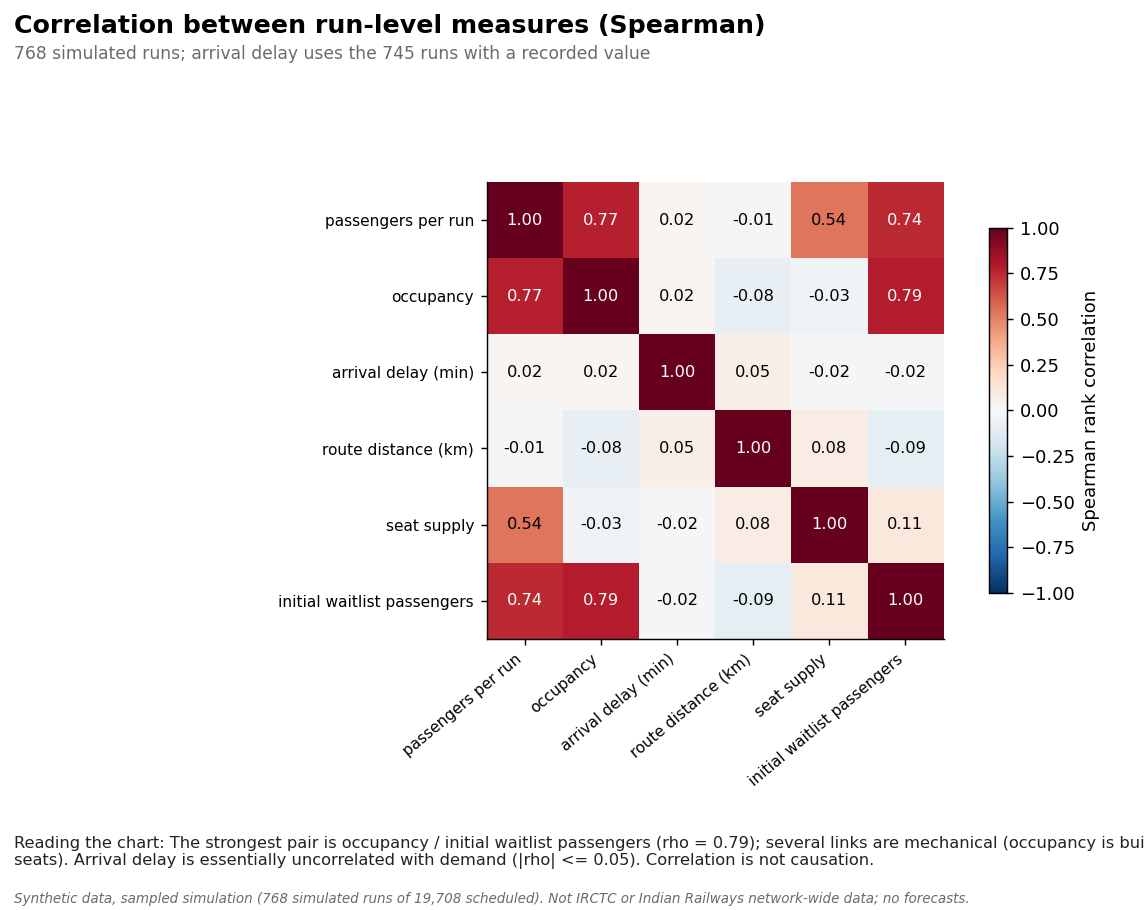

In [7]:
display(S['correlation_matrix'])
display(S['correlation_pairs'].sort_values('rho', key=abs, ascending=False))
display(Image(filename=str(ROOT / 'visuals' / 'phase5_python' / '15_correlation_heatmap.png')))

## 5. Grouped comparisons in charts

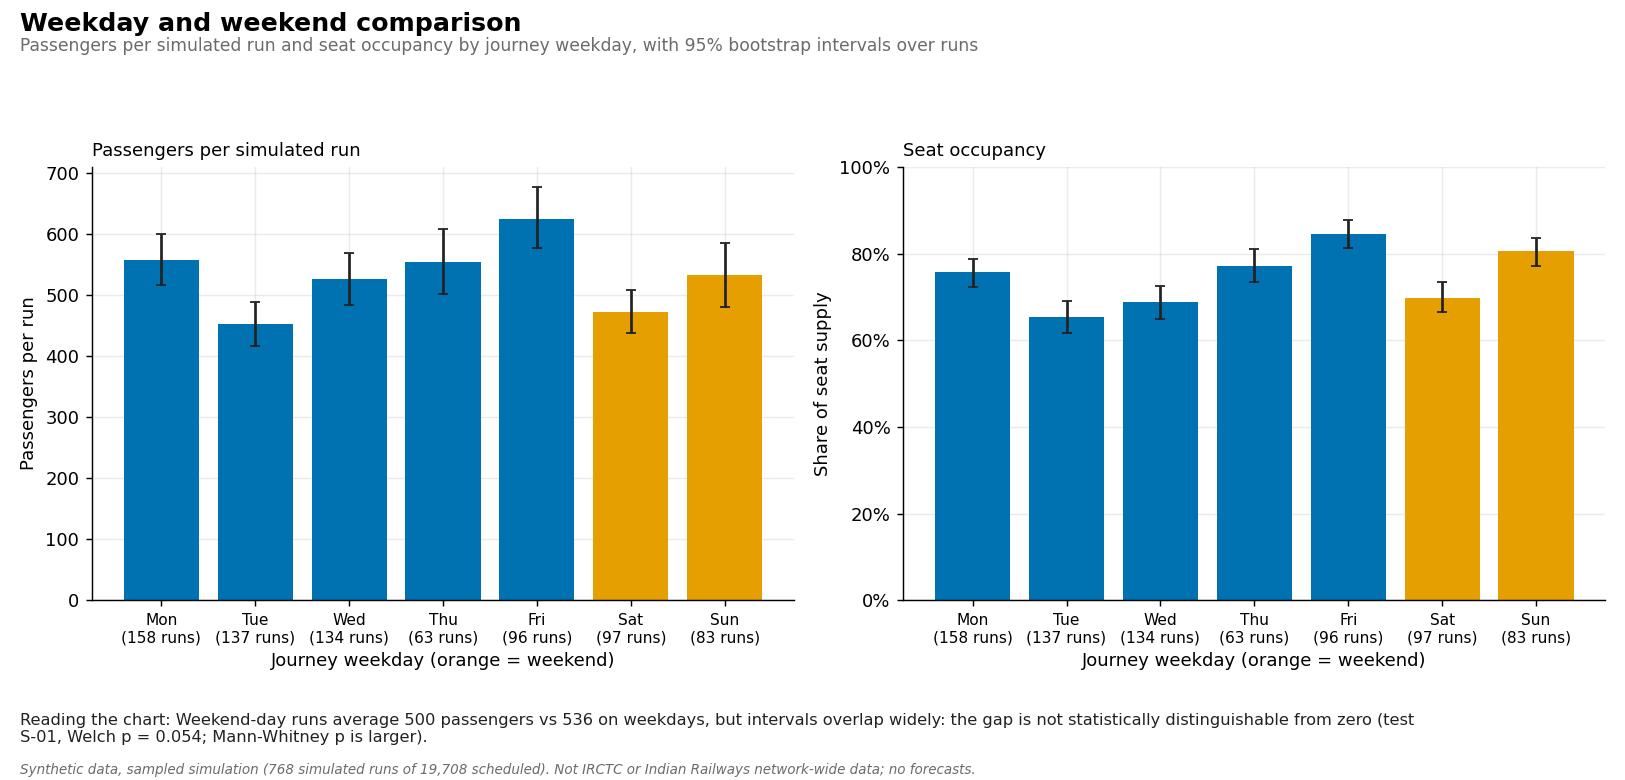

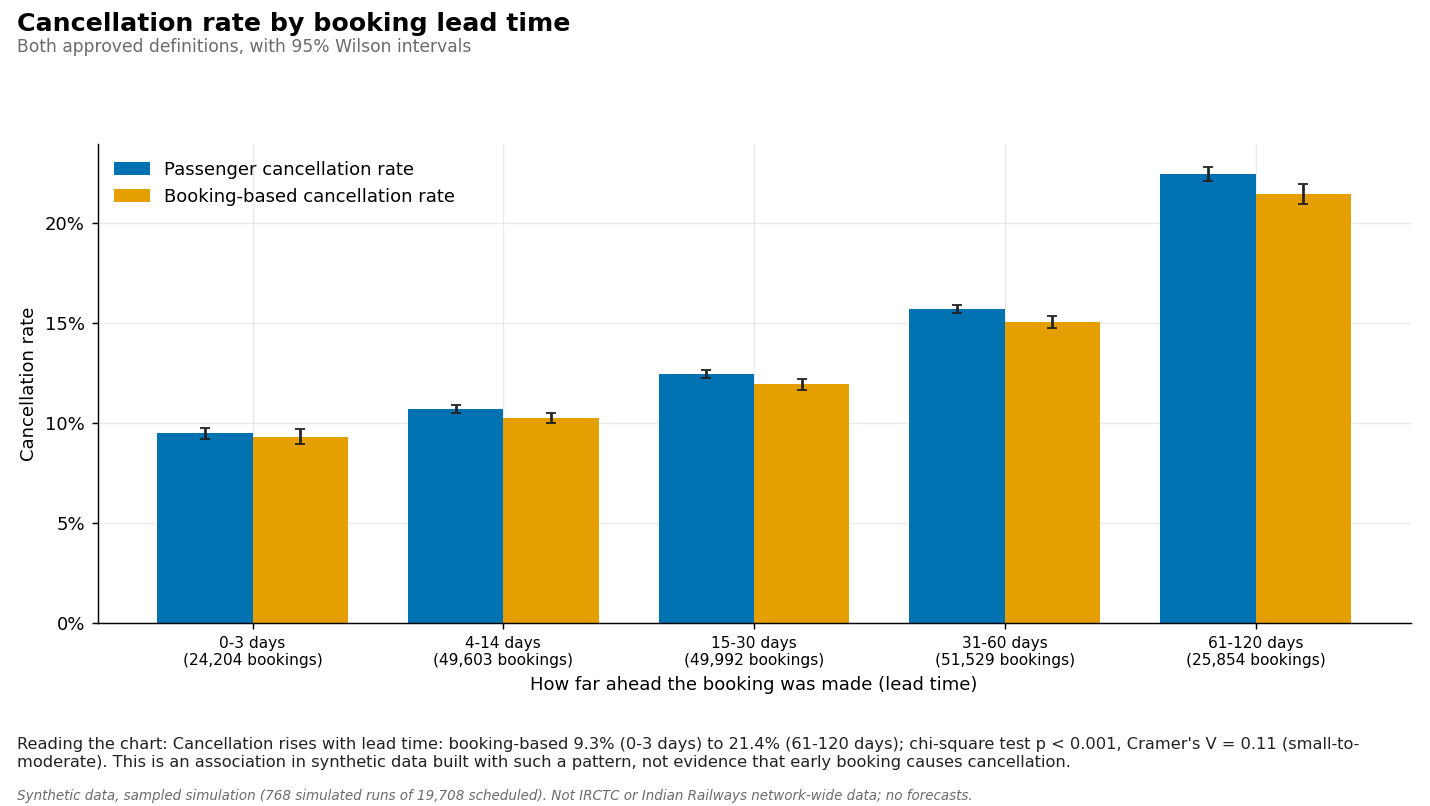

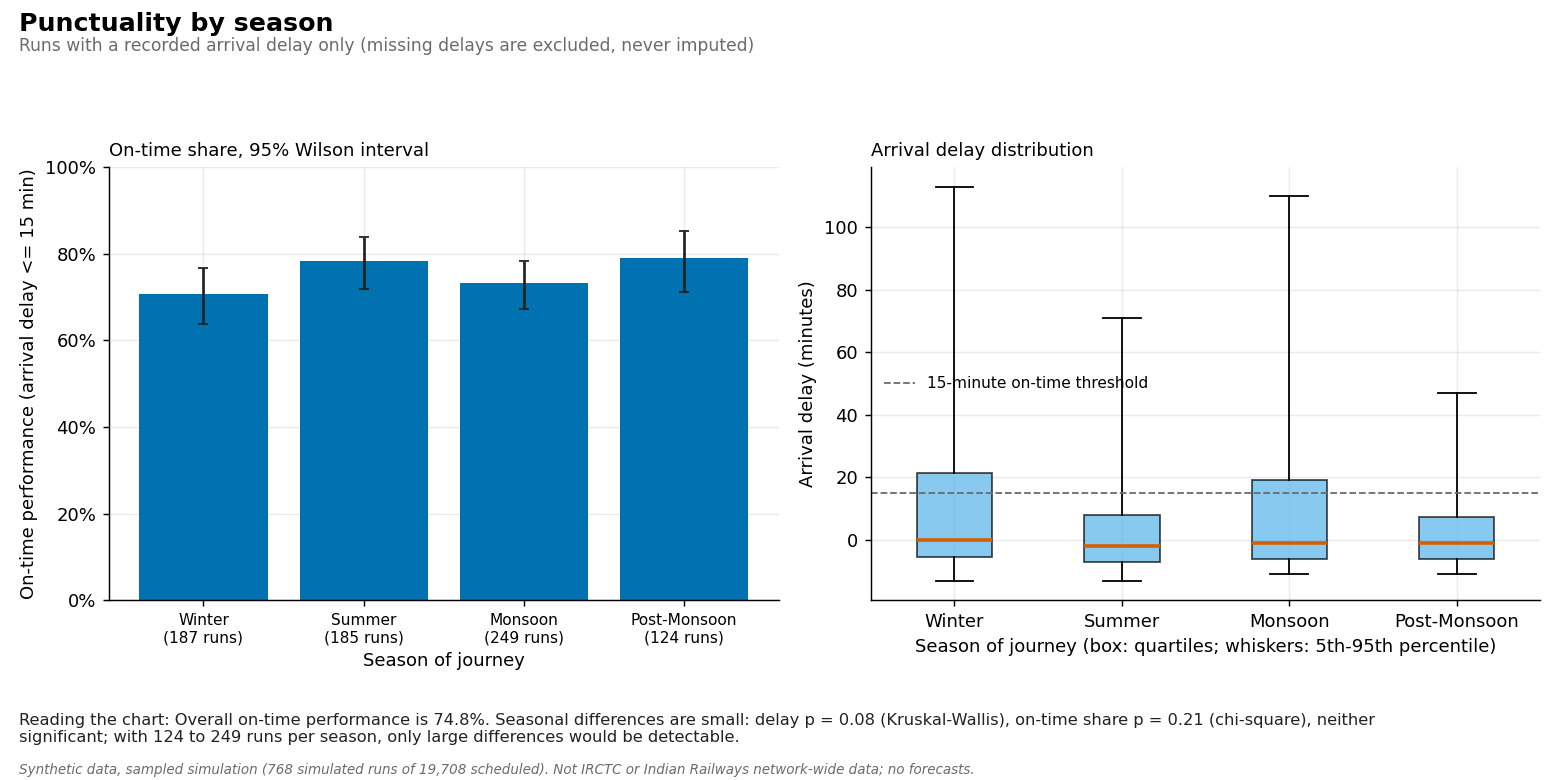

In [8]:
for f in ('12_weekday_weekend_comparison', '13_lead_time_vs_cancellation', '16_delay_and_otp_by_season'):
    display(Image(filename=str(ROOT / 'visuals' / 'phase5_python' / f'{f}.png')))